# Step 2b — EDA via SQL, Visualized in Python

**Input:** `sql/02_eda_queries.sql` (parsed for named queries), MySQL `customers` table
**Output:** 13 charts rendered inline below

Each query runs against MySQL, results come back as a pandas DataFrame, and
matplotlib/seaborn render the charts inline in the notebook.

In [1]:
import os
import sys


def find_project_root(marker="requirements.txt"):
    path = os.getcwd()
    for _ in range(5):
        if os.path.exists(os.path.join(path, marker)):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not locate project root (looked for {marker})")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, os.path.join(PROJECT_ROOT, "scripts"))
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

PROJECT_ROOT = C:\Users\DEVKUMAR\OneDrive\Desktop\DA_Project


In [2]:
import re

from plot_style import (
    CATEGORICAL, SEQUENTIAL_BLUE, CHURN_COLOR, RETAINED_COLOR,
    INK_SECONDARY, apply_style,
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils_db import get_connection

SQL_PATH = os.path.join(PROJECT_ROOT, "sql", "02_eda_queries.sql")

apply_style()


def save(fig, name):
    """Display inline. `name` is kept only as a descriptive label for each
    chart (matches the numbering used elsewhere in the project docs) --
    charts aren't written to disk, they live as outputs in this notebook."""
    plt.show()
    plt.close(fig)

## Parse the named queries out of `sql/02_eda_queries.sql`

In [3]:
def parse_named_queries(sql_text):
    """Split the .sql file into {name: query} using '-- === name ===' markers."""
    parts = re.split(r"^--\s*===\s*(\w+)\s*===\s*$", sql_text, flags=re.MULTILINE)
    queries = {}
    for i in range(1, len(parts), 2):
        name = parts[i].strip()
        sql = parts[i + 1].strip()
        queries[name] = sql
    return queries


def run_query(conn, sql):
    cur = conn.cursor()
    cur.execute(sql)
    cols = [d[0] for d in cur.description]
    rows = cur.fetchall()
    cur.close()
    return pd.DataFrame(rows, columns=cols)


with open(SQL_PATH, encoding="utf-8") as f:
    queries = parse_named_queries(f.read())

conn = get_connection()
results = {name: run_query(conn, sql) for name, sql in queries.items()}
conn.close()

for name, df in results.items():
    print(f"\n=== {name} ({len(df)} rows) ===")
    print(df.head(10).to_string(index=False))


=== overall_churn_rate (1 rows) ===
 total_customers churned_customers churn_rate_pct
            7043              1869          26.54

=== churn_by_contract (3 rows) ===
      Contract  customers churned churn_rate_pct avg_monthly_charges
Month-to-month       3875    1655          42.71               66.40
      One year       1473     166          11.27               65.05
      Two year       1695      48           2.83               60.77

=== churn_by_payment_method (4 rows) ===
            PaymentMethod  customers churn_rate_pct
         Electronic check       2365          45.29
             Mailed check       1612          19.11
Bank transfer (automatic)       1544          16.71
  Credit card (automatic)       1522          15.24

=== churn_by_internet_service (3 rows) ===
InternetService  customers churn_rate_pct avg_monthly_charges
    Fiber optic       3096          41.89               91.50
            DSL       2421          18.96               58.10
             No    

## Chart: churned vs retained (headline number)

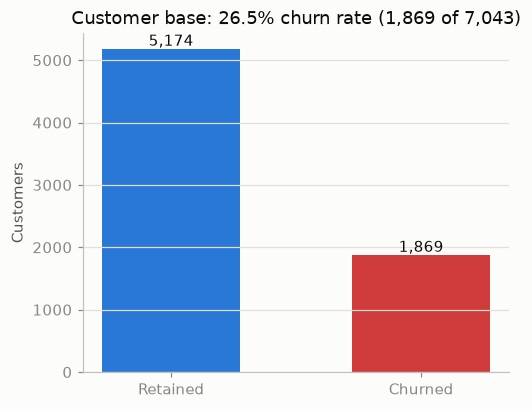

In [4]:
r = results["overall_churn_rate"]
fig, ax = plt.subplots(figsize=(5, 4))
labels = ["Retained", "Churned"]
values = [r["total_customers"][0] - r["churned_customers"][0], r["churned_customers"][0]]
colors = [RETAINED_COLOR, CHURN_COLOR]
bars = ax.bar(labels, values, color=colors, width=0.55)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=10)
ax.set_title(f"Customer base: {r['churn_rate_pct'][0]:.1f}% churn rate "
             f"({r['churned_customers'][0]:,} of {r['total_customers'][0]:,})")
ax.set_ylabel("Customers")
save(fig, "01_churned_vs_retained")

## Helper: generic bar-by-category chart

Reused for contract type, payment method, internet service, senior citizen.

In [5]:
def plot_bar_by_category(df, cat_col, val_col, title, xlabel, fname, sort_desc=True, pct=True):
    d = df.sort_values(val_col, ascending=not sort_desc)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(d[cat_col].astype(str), d[val_col], color=CATEGORICAL[0])
    for i, v in enumerate(d[val_col]):
        ax.text(v, i, f" {v:.1f}%" if pct else f" {v:,.0f}", va="center", fontsize=9, color=INK_SECONDARY)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    save(fig, fname)

## Chart: churn rate by contract type

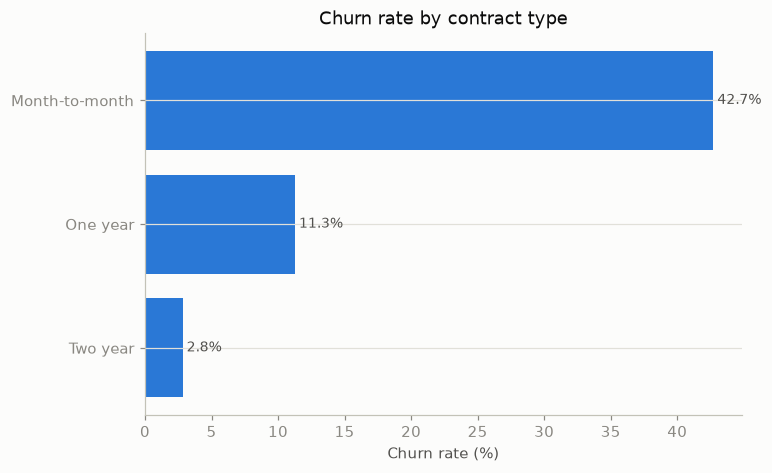

In [6]:
plot_bar_by_category(results["churn_by_contract"], "Contract", "churn_rate_pct",
                      "Churn rate by contract type", "Churn rate (%)", "02_churn_by_contract")

## Chart: churn rate by payment method

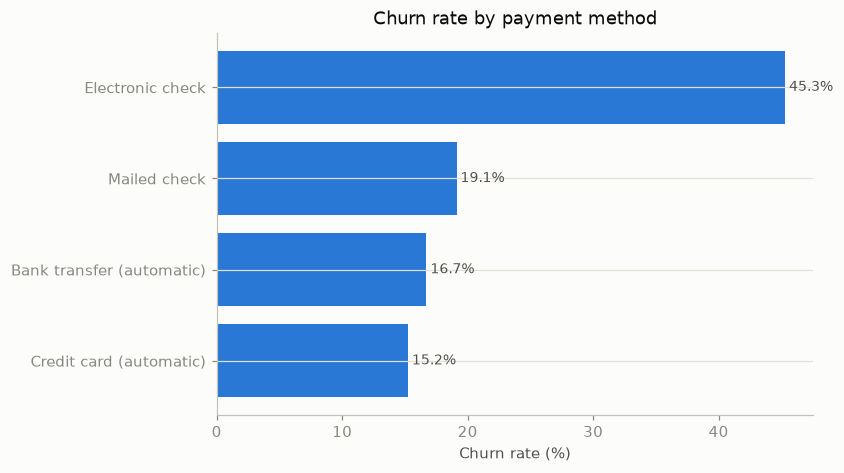

In [7]:
plot_bar_by_category(results["churn_by_payment_method"], "PaymentMethod", "churn_rate_pct",
                      "Churn rate by payment method", "Churn rate (%)", "03_churn_by_payment_method")

## Chart: churn rate by internet service

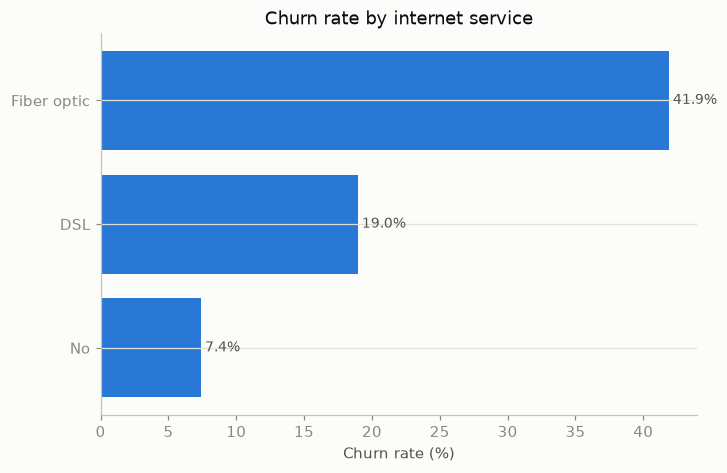

In [8]:
plot_bar_by_category(results["churn_by_internet_service"], "InternetService", "churn_rate_pct",
                      "Churn rate by internet service", "Churn rate (%)", "04_churn_by_internet_service")

## Chart: churn rate — senior citizen vs not

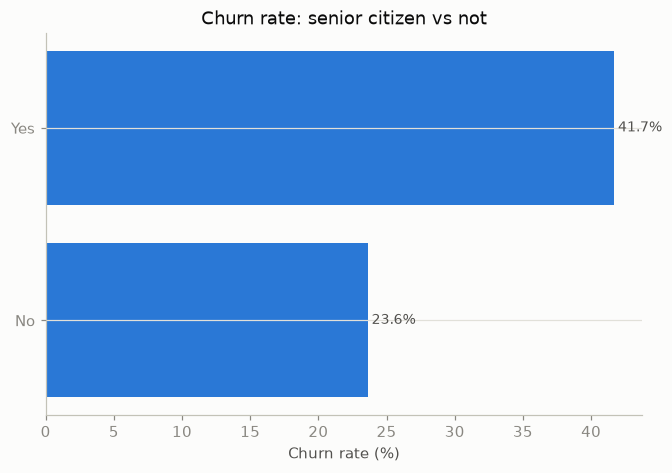

In [9]:
plot_bar_by_category(results["churn_by_senior_citizen"], "SeniorCitizen", "churn_rate_pct",
                      "Churn rate: senior citizen vs not", "Churn rate (%)", "05_churn_by_senior_citizen")

## Chart: churn rate by tenure band

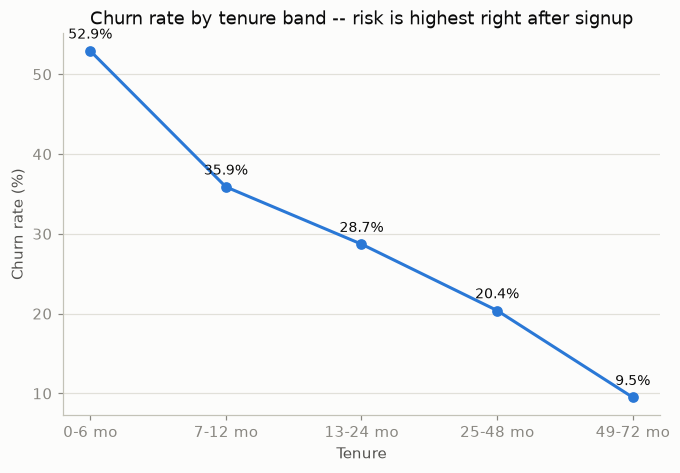

In [10]:
df = results["churn_by_tenure_bucket"]
order = ["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"]
d = df.set_index("tenure_bucket").reindex(order).reset_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(d["tenure_bucket"], d["churn_rate_pct"], marker="o", color=CATEGORICAL[0], linewidth=2)
for x, y in zip(d["tenure_bucket"], d["churn_rate_pct"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_title("Churn rate by tenure band -- risk is highest right after signup")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Tenure")
save(fig, "06_churn_by_tenure_bucket")

## Chart: charges & tenure by churn status

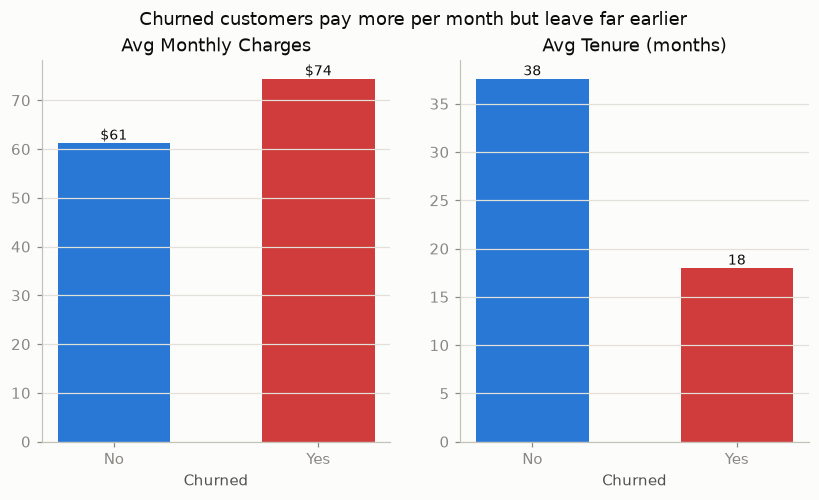

In [11]:
df = results["charges_by_churn_status"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
colors = [RETAINED_COLOR, CHURN_COLOR]
order = ["No", "Yes"]
d = df.set_index("Churn").reindex(order).reset_index()

axes[0].bar(d["Churn"], d["avg_monthly_charges"], color=colors, width=0.55)
axes[0].set_title("Avg Monthly Charges")
axes[0].set_xlabel("Churned")
for i, v in enumerate(d["avg_monthly_charges"]):
    axes[0].text(i, v, f"${v:.0f}", ha="center", va="bottom", fontsize=9)

axes[1].bar(d["Churn"], d["avg_tenure_months"], color=colors, width=0.55)
axes[1].set_title("Avg Tenure (months)")
axes[1].set_xlabel("Churned")
for i, v in enumerate(d["avg_tenure_months"]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)

fig.suptitle("Churned customers pay more per month but leave far earlier")
save(fig, "07_charges_tenure_by_churn")

## Chart: add-on services vs churn

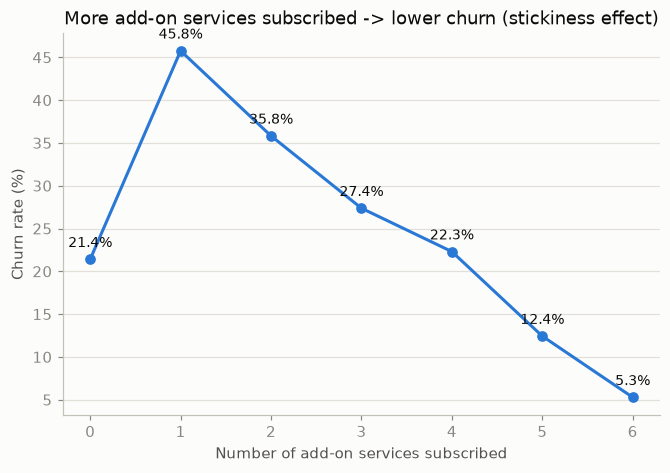

In [12]:
df = results["services_vs_churn"]
d = df.sort_values("NumServices")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(d["NumServices"], d["churn_rate_pct"], marker="o", color=CATEGORICAL[0], linewidth=2)
for x, y in zip(d["NumServices"], d["churn_rate_pct"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_title("More add-on services subscribed -> lower churn (stickiness effect)")
ax.set_xlabel("Number of add-on services subscribed")
ax.set_ylabel("Churn rate (%)")
ax.set_xticks(d["NumServices"])
save(fig, "08_services_vs_churn")

## Chart: revenue concentration (Pareto curve)

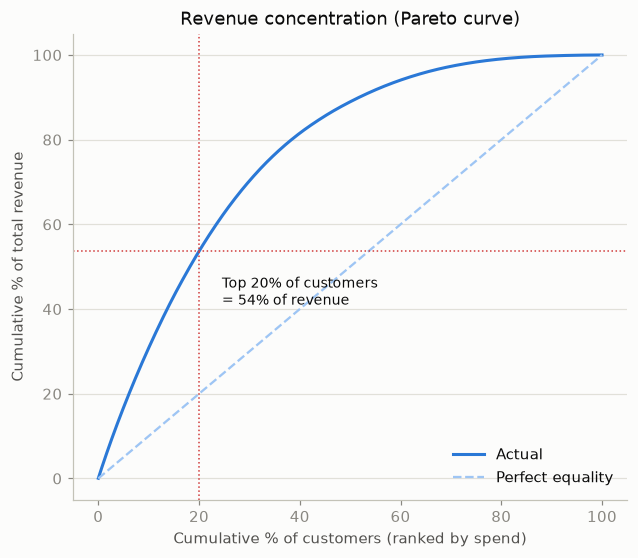

Top 20% of customers by spend generate 53.7% of total revenue


In [13]:
df = results["revenue_concentration"]
d = df.sort_values("TotalCharges", ascending=False).reset_index(drop=True)
n = len(d)
cum_customers = np.arange(1, n + 1) / n * 100
cum_revenue = d["TotalCharges"].cumsum() / d["TotalCharges"].sum() * 100

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(cum_customers, cum_revenue, color=CATEGORICAL[0], linewidth=2, label="Actual")
ax.plot([0, 100], [0, 100], color=SEQUENTIAL_BLUE[1], linewidth=1.5, linestyle="--", label="Perfect equality")

top20_revenue_share = cum_revenue[int(n * 0.2)]
ax.axvline(20, color=CHURN_COLOR, linewidth=1, linestyle=":")
ax.axhline(top20_revenue_share, color=CHURN_COLOR, linewidth=1, linestyle=":")
ax.annotate(f"Top 20% of customers\n= {top20_revenue_share:.0f}% of revenue",
            (20, top20_revenue_share), textcoords="offset points", xytext=(15, -35), fontsize=9)

ax.set_title("Revenue concentration (Pareto curve)")
ax.set_xlabel("Cumulative % of customers (ranked by spend)")
ax.set_ylabel("Cumulative % of total revenue")
ax.legend(loc="lower right", frameon=False)
save(fig, "09_revenue_concentration")
print(f"Top 20% of customers by spend generate {top20_revenue_share:.1f}% of total revenue")

## Chart: month-to-month vs longer contracts

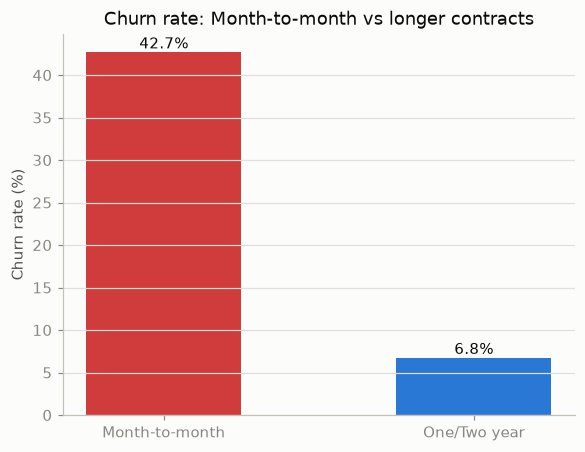

In [14]:
df = results["contract_length_comparison"]
order = ["Month-to-month", "One/Two year"]
d = df.set_index("contract_group").reindex(order).reset_index()
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(d["contract_group"], d["churn_rate_pct"], color=[CHURN_COLOR, RETAINED_COLOR], width=0.5)
for b, v in zip(bars, d["churn_rate_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=10)
ax.set_title("Churn rate: Month-to-month vs longer contracts")
ax.set_ylabel("Churn rate (%)")
save(fig, "10_contract_length_comparison")

## Chart: total revenue by payment method

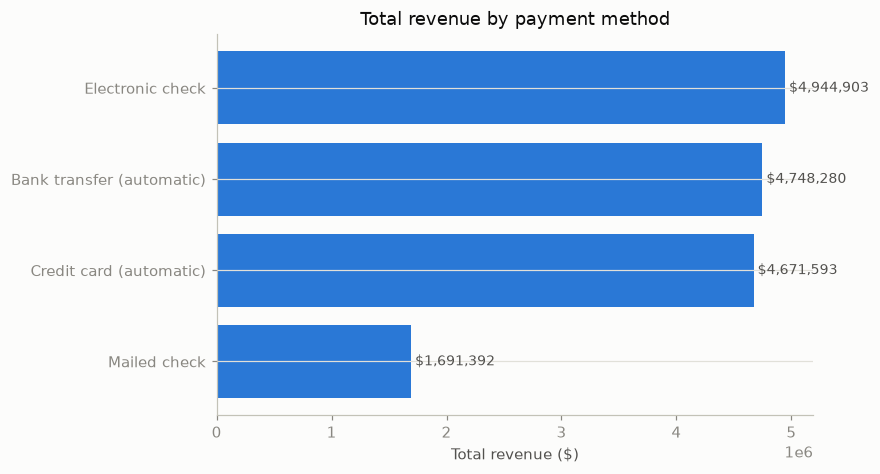

In [15]:
df = results["payment_method_revenue"]
d = df.sort_values("total_revenue", ascending=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(d["PaymentMethod"], d["total_revenue"], color=CATEGORICAL[0])
for i, v in enumerate(d["total_revenue"]):
    ax.text(v, i, f" ${v:,.0f}", va="center", fontsize=9, color=INK_SECONDARY)
ax.set_title("Total revenue by payment method")
ax.set_xlabel("Total revenue ($)")
save(fig, "11_payment_method_revenue")

## Chart: churn rate heatmap — contract x internet service

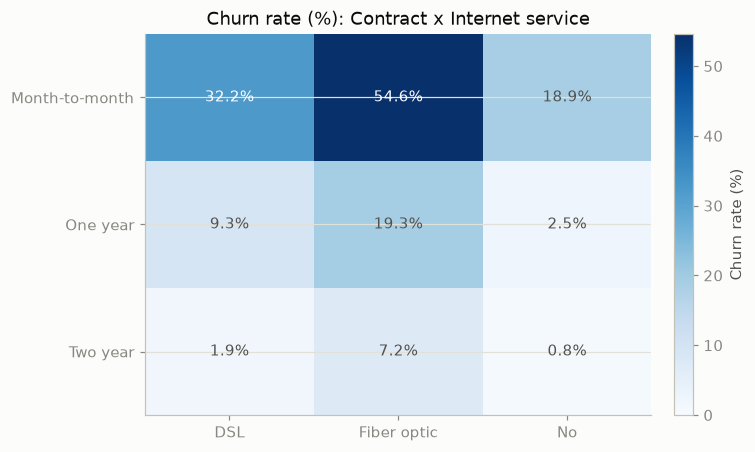

In [16]:
df = results["churn_heatmap_contract_internet"]
pivot = df.pivot(index="Contract", columns="InternetService", values="churn_rate_pct")
pivot = pivot.reindex(["Month-to-month", "One year", "Two year"])
pivot = pivot[["DSL", "Fiber optic", "No"]].astype(float)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto", vmin=0, vmax=pivot.values.max())
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        color = "white" if val > pivot.values.max() * 0.55 else INK_SECONDARY
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color=color, fontsize=10)
ax.set_title("Churn rate (%): Contract x Internet service")
fig.colorbar(im, ax=ax, label="Churn rate (%)", fraction=0.046, pad=0.04)
save(fig, "12_churn_heatmap_contract_internet")

## Chart: tenure distribution by churn status

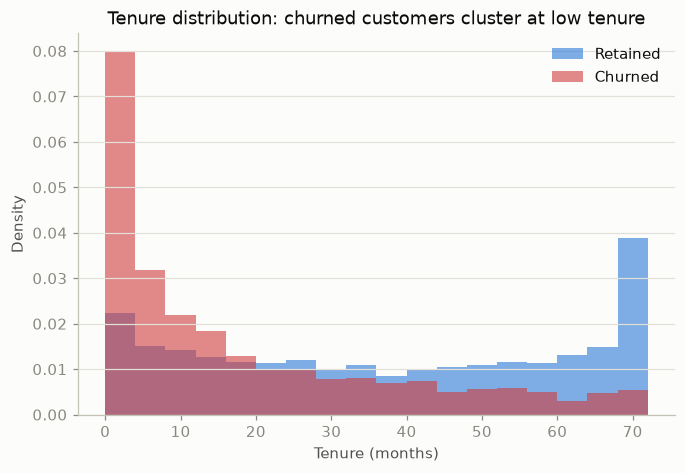

In [17]:
df = results["raw_tenure_charges_churn"]
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.arange(0, 76, 4)
ax.hist(df.loc[df["Churn"] == "No", "tenure"], bins=bins, alpha=0.6, color=RETAINED_COLOR, label="Retained", density=True)
ax.hist(df.loc[df["Churn"] == "Yes", "tenure"], bins=bins, alpha=0.6, color=CHURN_COLOR, label="Churned", density=True)
ax.set_title("Tenure distribution: churned customers cluster at low tenure")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Density")
ax.legend(frameon=False)
save(fig, "13_tenure_distribution_by_churn")